In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/edengonzalezz/eds220-hwk2.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

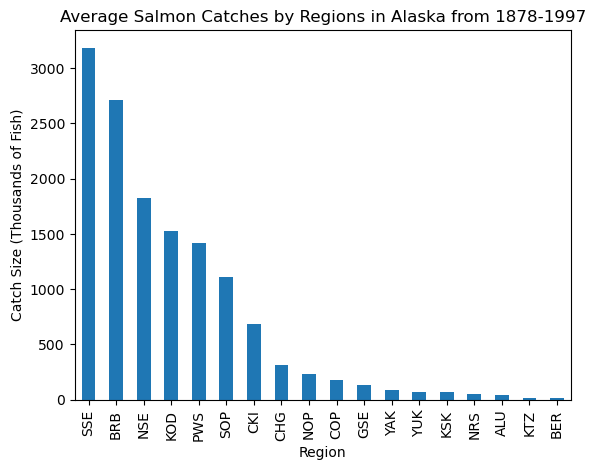

In [22]:
# FINAL CODE

# Import pandas 
import pandas as pd
import matplotlib.pyplot as plt

# Load the data 
catch_data = pd.read_csv('data/salmon_data.csv') 


# Select columns to keep by indexing the data frame with a list of columns to keep
catch_data = catch_data[['Region', 'Year', 'Species', 'Catch']]


# Replace the I with 1 by manually isolating that row and column, and reassigning its value to 1
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1

# Update the Catch column to contain integers only
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Group catch_data by region, then calculate average on the Catch column
avg_region = catch_data.groupby('Region').mean('Catch')

# Use bar graph to visualize the Catch sizes in each region in descending oder
avg_region['Catch'].sort_values(ascending = False).plot( 
    kind = 'bar', 
    xlabel = 'Region',
    ylabel = 'Catch Size (Thousands of Fish)', 
    title = "Average Salmon Catches by Regions in Alaska from 1878-1997"
)
# Output the plot
plt.show()

## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [12]:
# a.

# Import pandas 
import pandas as pd

# Load the data 
catch_data = pd.read_csv('data/salmon_data.csv') 

# Look at the first 5 rows 
catch_data.head()


,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [4]:
# b.
# Use the .info() method to explore the data
catch_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

I used the `.info()` method because it gives you a lot of fundamental information at once (number of columns, number of rows, non-null count and data type). From this method, I learned that the data has 5 columns, 8540 entries. Out of those 5 columns, only the `Year` column is numeric the rest are objects (characters). This method also revealed that `notesRegCode` has the most missing values, all other columns have no missing values. 

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [5]:
# First, subset the data frame to isolate the notesRegCode column, then use .unique() method
notes_unique = catch_data['notesRegCode'].unique()
# Look at the unique values in the column
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [6]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [7]:
# Select columns to keep by indexing the data frame with a list
catch_data = catch_data[['Region', 'Year', 'Species', 'Catch']]
# Verify the notesRegcCode column is no longer there
catch_data

,Region,Year,Species,Catch
0,SSE,1886,Chinook,0
1,SSE,1887,Chinook,0
2,SSE,1888,Chinook,0
3,SSE,1889,Chinook,0
4,SSE,1890,Chinook,0
...,...,...,...,...
8535,NOP,1993,Chum,135
8536,NOP,1994,Chum,84
8537,NOP,1995,Chum,99
8538,NOP,1996,Chum,68


In [8]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


The `Year` column is still the only numeric column, every other column contains strings as before. However, the `Catch` column should also have a numeric dtype. When we look at some of the values in the `Catch` column, there appear to be numbers, but they are in quotation marks. 

In [9]:
# Use the .info() method to inspect columns and their data type 
catch_data.info()

# The Catch column appears to contain numeric values
catch_data['Catch'].unique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Region   8540 non-null   object
 1   Year     8540 non-null   int64 
 2   Species  8540 non-null   object
 3   Catch    8540 non-null   object
dtypes: int64(1), object(3)
memory usage: 267.0+ KB


array(['0', '3', '4', ..., '709', '667', '393'], dtype=object)

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [10]:
# First attempt to alter the data type of Catch column
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [13]:
# Use str.contains() to find the row that contains I, then filter the data frame based on that condition
catch_I = catch_data[catch_data['Catch'].str.contains('I')]
# Inspect the row
catch_I

,Region,Year,notesRegCode,Species,Catch
400,GSE,1955,NaN,Chinook,I


In [14]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

In [15]:
# Replace the I with 1 by manually isolating that row and column, and reassigning its value 
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1

# Reassign updated row into new variable
catch_1 = catch_data.loc[400]

# Inspect the row
catch_1

Region              GSE
Year               1955
notesRegCode        NaN
Species         Chinook
Catch                 1
Name: 400, dtype: object

<!-- BEGIN QUESTION -->



<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [16]:
# Update the Catch column to contain integers only
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Store data type of the Catch column into a new variable 
catch_column_type = catch_data['Catch'].dtype

# Verify the data type was stored in the new variable
catch_column_type


dtype('int64')

In [17]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [18]:
# Group catch_data by region, then use the .mean() method on the Catch column to calculate mean catch
avg_region = catch_data.groupby('Region').mean('Catch')
avg_region

,Year,Catch
Region,,
ALU,1954.0,40.383908
BER,1946.5,16.372549
BRB,1940.5,2709.796491
CHG,1942.5,315.487273
CKI,1945.0,683.571429
COP,1950.5,179.223404
GSE,1918.5,133.841463
KOD,1939.5,1528.350000
KSK,1955.0,67.642353


In [19]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

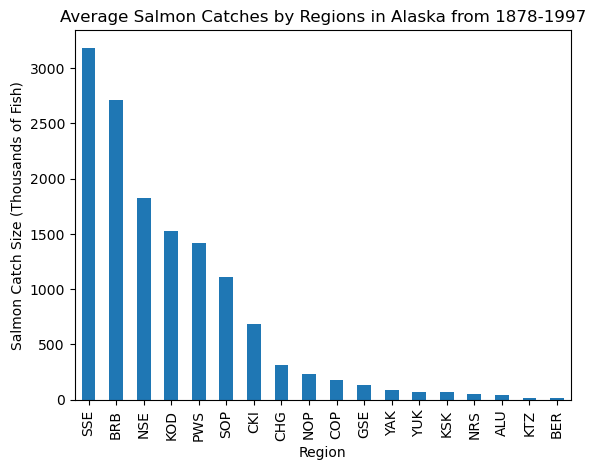

In [23]:
# Use bar graph to visualize the Catch sizes in each region
avg_region['Catch'].sort_values(
    ascending = False         # Sort values in descending order
    ).plot(
    kind = 'bar',             # Use bar graph
    xlabel = 'Region',        # Label
    ylabel = 'Salmon Catch Size (Thousands of Fish)', 
    title = "Average Salmon Catches by Regions in Alaska from 1878-1997"
)
# Output the plot
plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

On average from 1878 to 1997, Southern South East Alaska and Bristol Bay Management Area had the highest catch size with roughly 3000 and 2700 Thousands of fish, respectively. Though in general, the Southeastern coast of Alaksa had the highest catch sizes. Northern and more western regions, such as the Kotzebue Management Area and the Aleutian Islands Subarea, had the lowest catch sizes with about 18 and 40 Thousands of fish, respectively. Out of the 18 regions, 11 of them had Catch sizes of less than 500 Thousdands of Fish.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [21]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!